# Inspect Hele-Shaw results with Python

Run these five cells in order with **numpy, pandas and matplotlib** installed.
They inspect committed parameters, reference tolerances and the saved simulation
walkthrough. **No Docker, OpenFOAM, simulation, upload or network request is run.**
The original simulation notebook is read as JSON, never executed.

Tables and the comparison plot are recomputed from saved, rounded numbers.
The finger curves and final masks are original saved images, not newly computed
trajectories. Missing measurements remain missing. These are simulation
regression/sensitivity comparisons, not experimental validation.

The repository must already be cloned. Start inside it, in a parent directory
containing `hele-shaw-cells-example`, or set `HELE_SHAW_REPO` to its location.
The notebook works without internet after cloning.

## Contents
1. [Locate and verify sources](#1.-Locate-and-verify-sources)
2. [Inspect the parameter sweep](#2.-Inspect-the-parameter-sweep)
3. [Read saved results and missing values](#3.-Read-saved-results-and-missing-values)
4. [Check reference regression](#4.-Check-reference-regression)
5. [Compare recorded outcomes and figures](#5.-Compare-recorded-outcomes-and-figures)

[Companion Python source](inspect_results.py) ·
[Saved original walkthrough](Simulation_Walkthrough.html)

## 1. Locate and verify sources

In [1]:
from pathlib import Path
import os
import hashlib
import json
import base64
import io
import re
from html.parser import HTMLParser
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

def sha256(data):
    return hashlib.sha256(data).hexdigest()

def locate_repository():
    override = os.environ.get("HELE_SHAW_REPO")
    candidates = [Path(override).expanduser()] if override else []
    for parent in (Path.cwd(), *Path.cwd().parents):
        candidates.extend([parent, parent / "hele-shaw-cells-example",
                           parent / "work" / "hele-shaw-cells-example"])
    candidates.append(Path.home() / "work" / "hele-shaw-cells-example")
    for candidate in candidates:
        if (candidate / "parameters_1.json").is_file() and (candidate / "notebooks/Simulation_Walkthrough.ipynb").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Clone hele-shaw-cells-example first, then run from inside it or set HELE_SHAW_REPO to its absolute path. This inspection does not download files.")

ROOT = locate_repository()
REVISION = '8ec1b34f0a8fdbc103f35f88cba20e12b465800b'
EXPECTED_HASHES = {'parameters_1.json': 'f782185f028fdf7a71d609f8e545dae566d41a326eef8a63b4fc4a657d454c79', 'parameters_2.json': 'e3a3931663876bc3344cb8665509cafca6266c045f4391dcf44472ccbbb71692', 'parameters_3.json': 'a6dafc64cfd6f36e65dcf8571bbf91c17164cc8b423a048abb7414a0072f0549', 'tests/baseline/metrics_baseline.json': 'b0193c2d400248d24169b470174abaffcd80e7b9d7e979e3fde1639d5dc5780d', 'tests/baseline/metrics_tolerances.json': 'a9692fb18ae24801af40d902dc793639e440b30b979d1287bb9dc64638c49f4e', 'tests/compare.py': '99c16f64e0e1192e67993282b910f6caf1020e185b39e0e865585fcb2de2852b', 'notebooks/Simulation_Walkthrough.ipynb': '453b3a86d7cf7fb128437617936cfb6e55301a792b57691d9cfd7e03fbc0ba16'}

for name, expected in EXPECTED_HASHES.items():
    if sha256((ROOT / name).read_bytes()) != expected:
        raise ValueError(f"{name} differs from reviewed revision {REVISION}. Restore the reviewed scientific inputs before comparing results.")
OUT = ROOT / "docs/semantic/data/inspection"
OUT.mkdir(parents=True, exist_ok=True)
print(f"Verified {len(EXPECTED_HASHES)} committed scientific sources at {REVISION}.")
print("Only lightweight inspection runs below; the original notebook is never executed.")

Matplotlib is building the font cache; this may take a moment.


Verified 7 committed scientific sources at 8ec1b34f0a8fdbc103f35f88cba20e12b465800b.
Only lightweight inspection runs below; the original notebook is never executed.


## 2. Inspect the parameter sweep

Configuration 2 refines both in-plane mesh indices; configuration 3 doubles
inlet volumetric flow. Other supplied fields are checked for equality, so the
table describes the actual JSON files rather than stale notebook commentary.

In [2]:
parameters = {str(i): json.loads((ROOT / f"parameters_{i}.json").read_text()) for i in (1, 2, 3)}
parameter_table = pd.DataFrame([
    {"configuration": cfg, "NPA": p["mesh"]["NPA"], "NPZ": p["mesh"]["NPZ"],
     "NPB": p["mesh"]["NPB"], "flow_m3_s": p["boundary_conditions"]["inlet_volumetric_flow_rate"],
     "outer_radius_m": p["domain"]["R_out"], "gap_m": p["domain"]["b"],
     "end_time_s": p["solver"]["endTime"], "write_interval_s": p["solver"]["writeInterval"]}
    for cfg, p in parameters.items()
]).set_index("configuration")
def flatten(values, prefix=""):
    return {key: value for name, value in values.items()
            for key, value in (flatten(value, prefix + name + ".").items()
                               if isinstance(value, dict) else [(prefix + name, value)])}
reference_parameters = flatten(parameters["1"])
changes = [{"configuration": cfg, "parameter": key, "reference": reference_parameters[key], "value": value}
           for cfg in ("2", "3") for key, value in flatten(parameters[cfg]).items()
           if key != "configuration" and value != reference_parameters[key]]
assert {r["parameter"] for r in changes if r["configuration"] == "2"} == {"mesh.NPA", "mesh.NPZ"}
assert {r["parameter"] for r in changes if r["configuration"] == "3"} == {"boundary_conditions.inlet_volumetric_flow_rate"}
display(parameter_table)
display(pd.DataFrame(changes))
parameter_table.to_csv(OUT / "parameters.csv")

,NPA,NPZ,NPB,flow_m3_s,outer_radius_m,gap_m,end_time_s,write_interval_s
configuration,,,,,,,,
1,60,60,1,4.000000e-07,0.095,0.001,15.0,0.05
2,80,80,1,4.000000e-07,0.095,0.001,15.0,0.05
3,60,60,1,8.000000e-07,0.095,0.001,15.0,0.05


,configuration,parameter,reference,value
0,2,mesh.NPA,6.000000e+01,8.000000e+01
1,2,mesh.NPZ,6.000000e+01,8.000000e+01
2,3,boundary_conditions.inlet_volumetric_flow_rate,4.000000e-07,8.000000e-07


## 3. Read saved results and missing values

Read the saved HTML table in source cell 24 (zero-based index 23). It contains
three configurations and seven metrics. Radius values are displayed to six
decimal places; this inspection does not reconstruct hidden precision.
`None` becomes a missing numeric value (`NaN`), with no imputation or baseline
substitution. The original regression transcript is preserved separately.

In [3]:
walkthrough = json.loads((ROOT / "notebooks/Simulation_Walkthrough.ipynb").read_text())
class TableRows(HTMLParser):
    def __init__(self):
        super().__init__(); self.rows = []; self.row = []; self.value = None
    def handle_starttag(self, tag, attrs):
        if tag == "tr": self.row = []
        if tag in ("th", "td"): self.value = ""
    def handle_data(self, data):
        if self.value is not None: self.value += data
    def handle_endtag(self, tag):
        if tag in ("th", "td"):
            self.row.append(self.value.strip()); self.value = None
        if tag == "tr": self.rows.append(self.row)

saved_table_html = "".join(walkthrough["cells"][23]["outputs"][0]["data"]["text/html"])
parser = TableRows(); parser.feed(saved_table_html)
metric_names = parser.rows[0][1:]
source_rows = [row for row in parser.rows if row[0] in ("1", "2", "3")]
assert len(source_rows) == 3 and len(metric_names) == 7
saved_metrics = pd.DataFrame(
    [[np.nan if value in ("None", "NaN", "nan") else float(value) for value in row[1:]] for row in source_rows],
    index=pd.Index([row[0] for row in source_rows], name="configuration"), columns=metric_names)
missing_metrics = ["phase1_volume_fraction", "cumulative_continuity_error", "wall_time_seconds"]
assert saved_metrics[missing_metrics].isna().all().all()
assert saved_metrics.isna().sum().sum() == 9
display(saved_metrics)
display(saved_metrics.isna().rename_axis("configuration").rename(columns=lambda name: name + " missing"))
saved_metrics.to_csv(OUT / "recorded-metrics.csv", na_rep="")
saved_transcript = "".join(walkthrough["cells"][24]["outputs"][0]["text"])
(OUT / "original-regression-transcript.txt").write_text(saved_transcript)
print("Preserved 9 missing entries across 3 configurations. No missing metric was filled.")

,phase1_volume_fraction,cumulative_continuity_error,interface_length_proxy,wall_time_seconds,time_step_count,final_number_of_fingers,critical_radius_m
configuration,,,,,,,
1,NaN,NaN,2141.0,NaN,300.0,15.0,0.015833
2,NaN,NaN,3821.0,NaN,300.0,28.0,0.011875
3,NaN,NaN,2599.0,NaN,300.0,16.0,0.015833


,phase1_volume_fraction missing,cumulative_continuity_error missing,interface_length_proxy missing,wall_time_seconds missing,time_step_count missing,final_number_of_fingers missing,critical_radius_m missing
configuration,,,,,,,
1,True,True,False,True,False,False,False
2,True,True,False,True,False,False,False
3,True,True,False,True,False,False,False


Preserved 9 missing entries across 3 configurations. No missing metric was filled.


## 4. Check reference regression

Recompute descriptive tolerance decisions from the **rounded saved table**
against the committed configuration-1 baseline. All tolerances are absolute,
except wall time (relative); step count is exact. Missing inputs yield `SKIP`.
The original transcript passed the changed configuration as the `baseline`
argument; the current table labels reference and recorded values explicitly.
Its available absolute-tolerance decisions are unchanged.

Configuration 1 is the reference regression. Configurations 2 and 3 deliberately
change inputs; their out-of-tolerance values are sensitivity outcomes, not proof
of a defective solver. Passing this inspection is not a new simulation or an
experiment-versus-simulation validation.

In [4]:
baseline = json.loads((ROOT / "tests/baseline/metrics_baseline.json").read_text())
tolerances = json.loads((ROOT / "tests/baseline/metrics_tolerances.json").read_text())
comparisons = []
for cfg, values in saved_metrics.iterrows():
    for metric, recorded in values.items():
        reference = baseline[metric]
        tolerance = tolerances[metric]
        mode = "relative" if metric == "wall_time_seconds" else "absolute"
        delta = np.nan if pd.isna(recorded) else abs(recorded - reference)
        limit = tolerance * abs(reference) if mode == "relative" else tolerance
        status = "SKIP" if pd.isna(recorded) else ("PASS" if delta <= limit else "FAIL")
        comparisons.append(dict(configuration=cfg, metric=metric, reference=reference,
                                recorded=recorded, delta=delta, tolerance=tolerance,
                                tolerance_mode=mode, status=status))
comparison_table = pd.DataFrame(comparisons)
outcomes = pd.crosstab(comparison_table.configuration, comparison_table.status).reindex(columns=["PASS", "FAIL", "SKIP"], fill_value=0)
assert outcomes.loc["1"].tolist() == [4, 0, 3]
assert outcomes.loc["2"].tolist() == [2, 2, 3]
assert outcomes.loc["3"].tolist() == [3, 1, 3]
recorded_decisions = {}
current = None
for line in saved_transcript.splitlines():
    match = re.search(r"Smoke test: configuration (\d+)", line)
    if match: current = match.group(1)
    match = re.match(r"compare.py: (\w+): (PASS|FAIL|SKIP)", line)
    if match: recorded_decisions[(current, match.group(1))] = match.group(2)
assert all(recorded_decisions[(r.configuration, r.metric)] == r.status for r in comparison_table.itertuples())
display(comparison_table)
display(outcomes)
comparison_table.to_csv(OUT / "recomputed-comparisons.csv", index=False, na_rep="")
outcomes.to_csv(OUT / "comparison-summary.csv")
print("All 21 recomputed status decisions match the saved transcript (including 9 skipped checks).")

,configuration,metric,reference,recorded,delta,tolerance,tolerance_mode,status
0,1,phase1_volume_fraction,0.21180,NaN,NaN,0.050,absolute,SKIP
1,1,cumulative_continuity_error,0.00056,NaN,NaN,0.001,absolute,SKIP
2,1,interface_length_proxy,2141.00000,2141.000000,0.000000,50.000,absolute,PASS
3,1,wall_time_seconds,1100.00000,NaN,NaN,0.300,relative,SKIP
4,1,time_step_count,300.00000,300.000000,0.000000,0.000,absolute,PASS
5,1,final_number_of_fingers,15.00000,15.000000,0.000000,5.000,absolute,PASS
6,1,critical_radius_m,0.01580,0.015833,0.000033,0.005,absolute,PASS
7,2,phase1_volume_fraction,0.21180,NaN,NaN,0.050,absolute,SKIP
8,2,cumulative_continuity_error,0.00056,NaN,NaN,0.001,absolute,SKIP
9,2,interface_length_proxy,2141.00000,3821.000000,1680.000000,50.000,absolute,FAIL


status,PASS,FAIL,SKIP
configuration,,,
1,4,0,3
2,2,2,3
3,3,1,3


All 21 recomputed status decisions match the saved transcript (including 9 skipped checks).


## 5. Compare recorded outcomes and figures

The first figure is **newly plotted from recorded scalar values**. A mesh-dependent
interface proxy is not a physical interface length, and this three-case comparison
does not establish mesh convergence. Radii retain the saved table's precision.

The following six figures are **exact saved PNGs** from source cell 31
(zero-based index 30): for each configuration, finger count over time, then the
final binary mask. Their raw numeric time series are not committed here. They
are redisplayed without tracing, interpolation or a new finger extraction run.

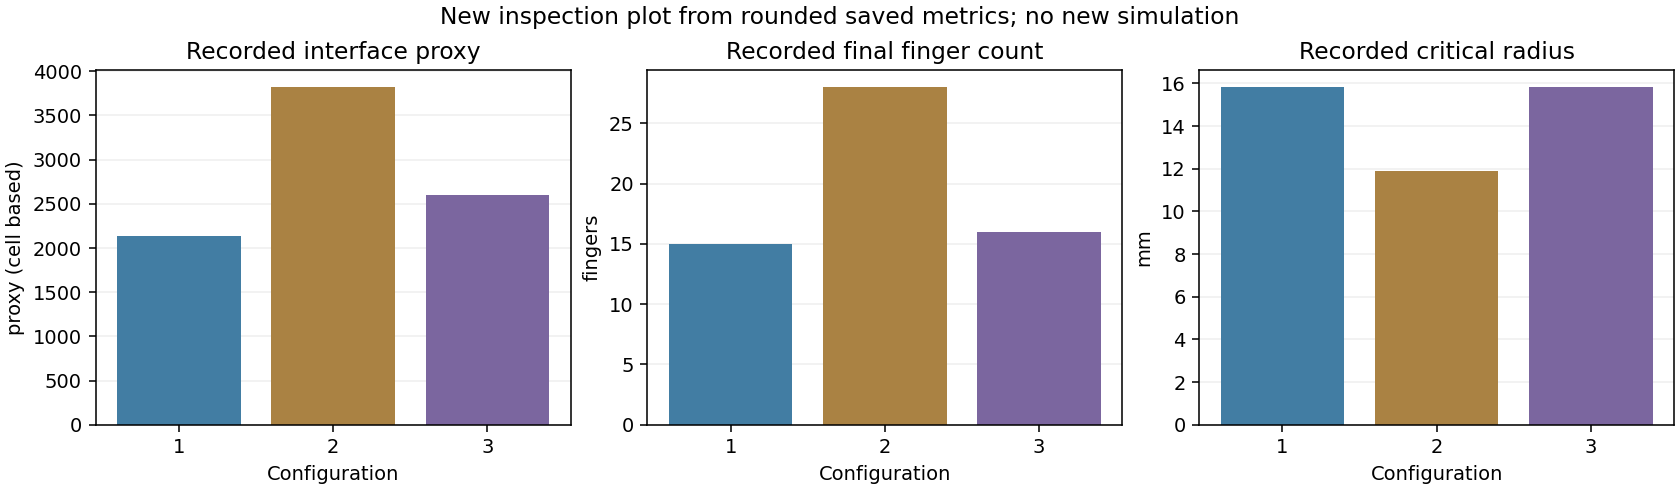

### Configuration 1: saved curve and final mask

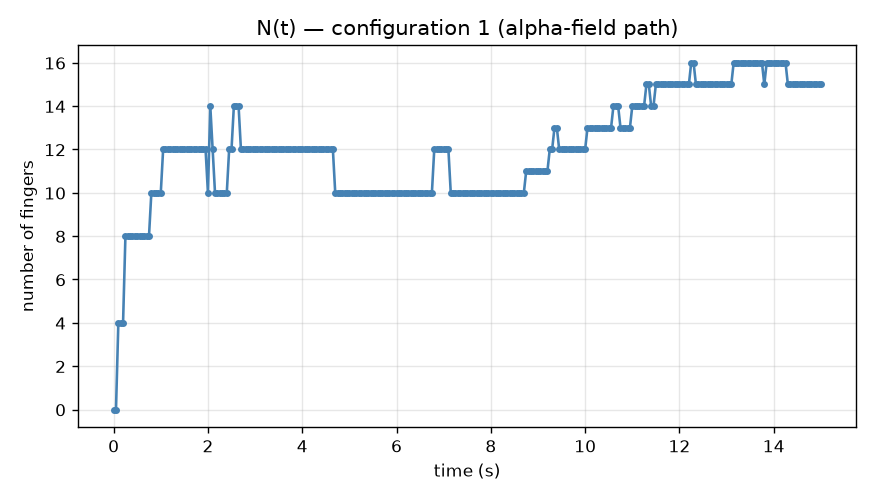

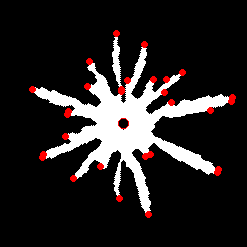

### Configuration 2: saved curve and final mask

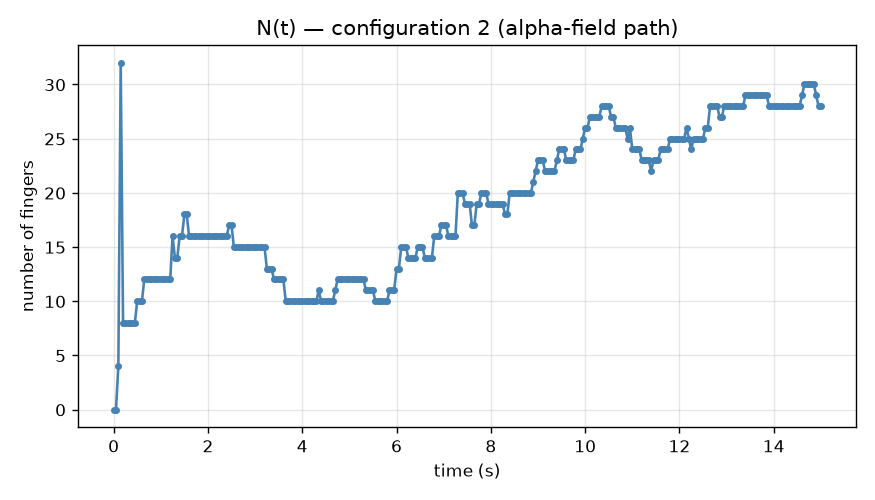

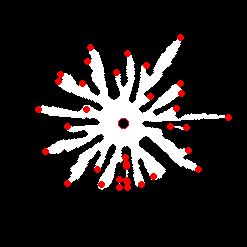

### Configuration 3: saved curve and final mask

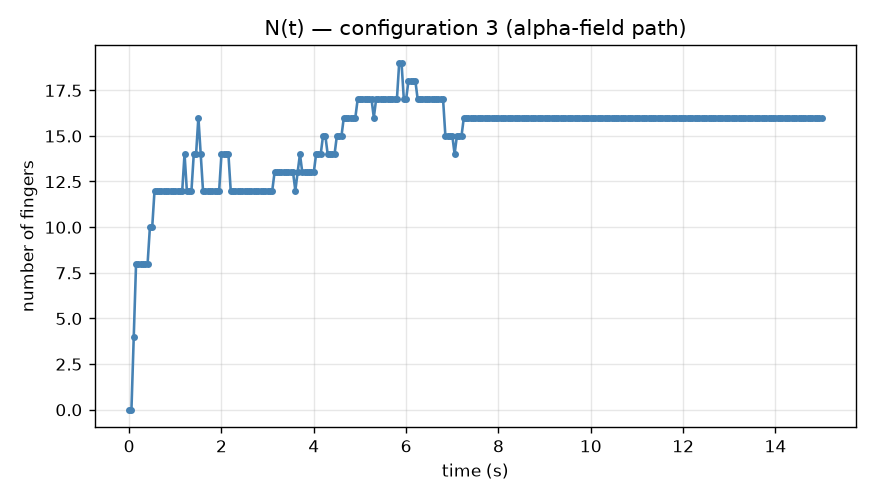

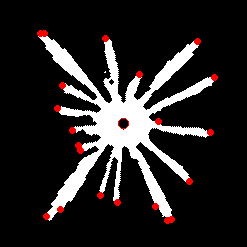

Saved inspection tables, the new scalar comparison plot, and exact original figures with provenance.


In [5]:
figure, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
colors = ["#427da3", "#aa8243", "#7b669f"]
plot_specs = [("interface_length_proxy", "Recorded interface proxy", "proxy (cell based)", 1),
              ("final_number_of_fingers", "Recorded final finger count", "fingers", 1),
              ("critical_radius_m", "Recorded critical radius", "mm", 1000)]
for ax, (metric, title, unit, scale) in zip(axes, plot_specs):
    ax.bar(saved_metrics.index, saved_metrics[metric] * scale, color=colors)
    ax.set(title=title, xlabel="Configuration", ylabel=unit)
    ax.grid(axis="y", alpha=.2); ax.set_axisbelow(True)
figure.suptitle("New inspection plot from rounded saved metrics; no new simulation")
figure.savefig(OUT / "recorded-outcomes.png", dpi=140)
display(Image(filename=str(OUT / "recorded-outcomes.png")))
plt.close(figure)
image_provenance = []
for cfg, output_indices in (("1", (1, 2)), ("2", (4, 5)), ("3", (7, 8))):
    display(Markdown(f"### Configuration {cfg}: saved curve and final mask"))
    for kind, output_index in zip(("finger-count-curve", "final-mask"), output_indices):
        image_data = base64.b64decode(walkthrough["cells"][30]["outputs"][output_index]["data"]["image/png"])
        image_name = f"saved-config-{cfg}-{kind}.png"
        (OUT / image_name).write_bytes(image_data)
        image_provenance.append(dict(configuration=cfg, kind=kind, sourceCellIndex=30,
                                     sourceOutputIndex=output_index, file=image_name, sha256=sha256(image_data)))
        display(Image(data=image_data))
report = {"revision": REVISION, "sources": EXPECTED_HASHES,
          "simulationExecuted": False, "originalNotebookExecuted": False,
          "uploadExecuted": False, "numericTrajectoriesAvailable": False,
          "metricPrecision": "Exactly the saved HTML table; radius rounded to 6 decimals",
          "missingMetricEntries": int(saved_metrics.isna().sum().sum()),
          "statusDecisionsMatchSavedTranscript": True,
          "newPlot": "recorded-outcomes.png", "savedImages": image_provenance}
(OUT / "provenance.json").write_text(json.dumps(report, indent=2) + "\n")
print("Saved inspection tables, the new scalar comparison plot, and exact original figures with provenance.")